# Práctica 1 – Clasificación de estilos artísticos con redes convolucionales

**Aprendizaje Automático II · 2026-27**

Clasificador de imágenes de cuadros en 7 estilos artísticos (*Baroque, Cubism, Impressionism, Minimalism, Pointillism, Pop Art, Ukiyo-e*) con 300 imágenes por clase (2100 en total), implementado en PyTorch con redes convolucionales, pooling, dropout y parada anticipada.

## 1. Carga de datos

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# raíz
raiz_AA2 = '/content/drive/MyDrive/PROYECTO AA2'

In [3]:
import torch
from torch.utils.data import DataLoader
from torchvision.datasets import ImageFolder
from torchvision import transforms
import matplotlib.pyplot as plt
import os

In [4]:
transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor()
])

In [5]:
ruta_dataset = os.path.join(raiz_AA2, 'dataset')

dataset = ImageFolder(
    root=ruta_dataset,
    transform=transform
)

print("Número de imágenes:", len(dataset))
print("Clases:", dataset.classes)
print("Etiquetas:", dataset.class_to_idx)

Número de imágenes: 2100
Clases: ['Baroque', 'Cubism', 'Impressionism', 'Minimalism', 'Pointillism', 'Pop_Art', 'Ukiyo']
Etiquetas: {'Baroque': 0, 'Cubism': 1, 'Impressionism': 2, 'Minimalism': 3, 'Pointillism': 4, 'Pop_Art': 5, 'Ukiyo': 6}


In [6]:
import numpy as np
from sklearn.model_selection import train_test_split

indices = np.arange(len(dataset))
etiquetas = dataset.targets

In [7]:
indices_train, indices_temp = train_test_split(
    indices,
    test_size=0.30,
    stratify=etiquetas,
    random_state=42
)

indices_val, indices_test = train_test_split(
    indices_temp,
    test_size=0.50,
    stratify=np.array(etiquetas)[indices_temp],
    random_state=42
)

print("Entrenamiento:", len(indices_train))
print("Validación:", len(indices_val))
print("Test:", len(indices_test))

Entrenamiento: 1470
Validación: 315
Test: 315


In [8]:
from torch.utils.data import Subset

train_dataset = Subset(dataset, indices_train)
val_dataset = Subset(dataset, indices_val)
test_dataset = Subset(dataset, indices_test)

loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

In [9]:
# Acceder a los datos por lotes
for X, y in loader:
    print(f'Tamaño batch X: {X.shape}')
    print(f'Tamaño batch y: {y.shape}')
    print(X)
    print(f'Etiquetas: {y}')
    break

Tamaño batch X: torch.Size([32, 3, 128, 128])
Tamaño batch y: torch.Size([32])
tensor([[[[0.1569, 0.1843, 0.1686,  ..., 0.1255, 0.1333, 0.1333],
          [0.1490, 0.1373, 0.1490,  ..., 0.0941, 0.1412, 0.1176],
          [0.1569, 0.1569, 0.1725,  ..., 0.0941, 0.1412, 0.1255],
          ...,
          [0.1176, 0.1294, 0.1373,  ..., 0.2157, 0.2471, 0.2471],
          [0.1176, 0.1137, 0.1569,  ..., 0.1765, 0.1882, 0.1451],
          [0.1098, 0.0980, 0.1412,  ..., 0.2118, 0.2196, 0.2157]],

         [[0.1451, 0.1529, 0.1490,  ..., 0.1059, 0.1216, 0.1255],
          [0.1412, 0.1216, 0.1255,  ..., 0.0863, 0.1098, 0.1098],
          [0.1373, 0.1333, 0.1569,  ..., 0.0863, 0.1059, 0.1216],
          ...,
          [0.0863, 0.0863, 0.0902,  ..., 0.1765, 0.2039, 0.1843],
          [0.0941, 0.0902, 0.0980,  ..., 0.1098, 0.1255, 0.1098],
          [0.0941, 0.0824, 0.0863,  ..., 0.1176, 0.1176, 0.1373]],

         [[0.1412, 0.1333, 0.1294,  ..., 0.0863, 0.1059, 0.1216],
          [0.1294, 0.1137, 0.

Dimensiones del batch de imágenes: torch.Size([32, 3, 128, 128])
Dimensiones del batch de etiquetas: torch.Size([32])


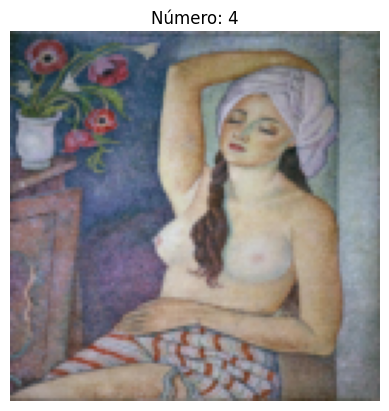

In [10]:
# Obtenemos una imagen del dataloader de entrenamiento
dataiter = iter(loader)
imagenes, etiquetas = next(dataiter)

print(f'Dimensiones del batch de imágenes: {imagenes.size()}')
print(f'Dimensiones del batch de etiquetas: {etiquetas.size()}')

# Permutamos las dimensiones: canales, ancho, alto -> ancho, alto, canales, y convertimos a numpy
imagen = imagenes[0].permute(1, 2, 0)
imagen = imagen.numpy()

# Visualizamos la imagen
plt.axis("off")
plt.title(f'Número: {etiquetas[0].item()}')
plt.imshow(imagen)
plt.show()

In [11]:

import torch.nn as nn
import torch.nn.functional as F

class ConvNet(nn.Module):
  def __init__(self):
    super(ConvNet,self).__init__()
    # primera capa convolucional: 3 canales de entrada (RGB), 16 filtros, tamaño del kernel 5x5
    self.conv1 = nn.Conv2d(in_channels=3, out_channels=16, kernel_size=5, stride=1, padding=2)

    # segunda capa convolucional: 16 canales de entrada, 32 filtros, tamaño del kernel 5x5
    self.conv2 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=5, stride=1, padding=2)

    # tercera capa convolucional: 32 canales de entrada, 64 filtros, tamaño del kernel 5x5
    self.conv3 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=5, stride=1, padding=2)

    # capa de pooling (muestreo): tamaño del kernel 2x2, stride 2
    self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2, padding=0)

    # capa de dropout para evitar overfitting
    self.dropout1 = nn.Dropout(p=0.25)

    # capas totalmente conectadas (fully connected layers)
    self.fc1 = nn.Linear(64*16*16, 128)
    # cuarta capa totalmente conectada: 128 neuronas, 7 salidas (una por cada clase)
    self.fc2 = nn.Linear(128, 7)

  def forward(self,x):
    # primer bloque convolucional: conv -> relu -> pool
    x = self.conv1(x)
    x = F.relu(x)
    x = self.pool1(x) # x es un tensor de 64x64 x 16 características

    # segundo bloque convolucional: conv -> relu -> pool
    x = self.pool1(F.relu(self.conv2(x))) # 32x32 x 32 características

    # tercer bloque convolucional: conv -> relu -> pool
    x = self.pool1(F.relu(self.conv3(x))) # 16x16 x 64 características

    # convierte la salida de la última capa convolucional en un vector 1D para la capa totalmente conectada. view es similar a reshape en numpy
    x = x.view(-1, 64*16*16)

    x = F.relu(self.fc1(x))
    x = self.dropout1(x)

    x = self.fc2(x)

    return x


In [12]:
import torch
import torch.optim as optim

# detección si hay una GPU disponible, si no, se usará la CPU
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'*** Utilizando {device}')

# definimos el modelo, la función de pérdida y el optimizador
modelo = ConvNet().to(device)
criterio = nn.CrossEntropyLoss()
optimizador = optim.Adam(modelo.parameters(), lr = 0.001)

print(f'*** Modelo cargado')

# indicamos el número de épocas
epocas = 20

*** Utilizando cuda
*** Modelo cargado


In [13]:

import copy

valores_perdida_train = []
valores_perdida_validacion = []

mejor_perdida = float('inf')
paciencia = 5
epocas_sin_mejora = 0

print('*** Comienza entrenamiento')

# bucle principal de entrenamiento
for epoca in range(epocas):

  modelo.train()

  train_loss = 0.0
  for images, labels in loader:

    # enviamos las imágenes y etiquetas al dispositivo (GPU o CPU)
    images, labels = images.to(device), labels.to(device)

    # resetear los gradientes del optimizador
    optimizador.zero_grad()

    # calculamos la salida del modelo, la pérdida y realizamos backpropagation
    outputs = modelo(images)
    loss = criterio(outputs, labels)
    loss.backward()
    optimizador.step()

    train_loss += loss.item()

  valores_perdida_train.append(train_loss/len(loader))

  with torch.no_grad():
    modelo.eval()

    valid_loss = 0.0
    for images, labels in val_loader:
      images, labels = images.to(device), labels.to(device)
      outputs = modelo(images)
      loss = criterio(outputs, labels)
      valid_loss += loss.item()

    valid_loss = valid_loss/len(val_loader)
    valores_perdida_validacion.append(valid_loss)

  print(f'Época {epoca+1:2d}, train loss: {valores_perdida_train[-1]:.4f} validation loss: {valid_loss:.4f}')

  # parada anticipada
  if valid_loss < mejor_perdida:
    mejor_perdida = valid_loss
    mejor_modelo = copy.deepcopy(modelo.state_dict())
    epocas_sin_mejora = 0
  else:
    epocas_sin_mejora += 1

  if epocas_sin_mejora >= paciencia:
    print('*** Parada anticipada')
    break

modelo.load_state_dict(mejor_modelo)


*** Comienza entrenamiento


KeyboardInterrupt: 

In [ ]:
modelo.eval()

correctas = 0
total = 0

with torch.no_grad():
    for images, labels in val_loader:
        images, labels = images.to(device), labels.to(device)

        outputs = modelo(images)
        _, predicciones = torch.max(outputs, 1)

        total += labels.size(0)
        correctas += (predicciones == labels).sum().item()

accuracy = 100 * correctas / total

print(f'Accuracy de validación: {accuracy:.2f}%')

In [ ]:
plt.plot(valores_perdida_train, label='Entrenamiento')
plt.plot(valores_perdida_validacion, label='Validación')

plt.xlabel('Épocas')
plt.ylabel('Pérdida')
plt.title('Evolución de la pérdida')
plt.legend()
plt.show()

In [ ]:
import shutil

ruta_dataset_local = '/content/dataset'

shutil.copytree(ruta_dataset, ruta_dataset_local, dirs_exist_ok=True)

print('Dataset copiado correctamente')

In [ ]:
dataset = ImageFolder(root=ruta_dataset_local, transform=transform)

train_dataset = Subset(dataset, indices_train)
val_dataset = Subset(dataset, indices_val)
test_dataset = Subset(dataset, indices_test)

loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

print("Entrenamiento:", len(train_dataset))
print("Validación:", len(val_dataset))
print("Test:", len(test_dataset))

In [20]:
resultados = []

resultados.append({
    'Configuración': 1,
    'Learning rate': 0.001,
    'Batch size': 32,
    'Filtros': '16, 32, 64',
    'Dropout': 0.25,
    'Épocas': 11,
    'Mejor val loss': 1.6197,
    'Accuracy validación': 40.95
})

In [ ]:
# Configuración 2
modelo = ConvNet().to(device)
criterio = nn.CrossEntropyLoss()
optimizador = optim.Adam(modelo.parameters(), lr=0.0001)

epocas = 20

In [ ]:
import copy

valores_perdida_train = []
valores_perdida_validacion = []

mejor_perdida = float('inf')
paciencia = 5
epocas_sin_mejora = 0

print('*** Comienza entrenamiento configuración 2')

for epoca in range(epocas):

  modelo.train()

  train_loss = 0.0
  for images, labels in loader:

    images, labels = images.to(device), labels.to(device)

    optimizador.zero_grad()

    outputs = modelo(images)
    loss = criterio(outputs, labels)
    loss.backward()
    optimizador.step()

    train_loss += loss.item()

  valores_perdida_train.append(train_loss/len(loader))

  with torch.no_grad():
    modelo.eval()

    valid_loss = 0.0
    for images, labels in val_loader:
      images, labels = images.to(device), labels.to(device)
      outputs = modelo(images)
      loss = criterio(outputs, labels)
      valid_loss += loss.item()

    valid_loss = valid_loss/len(val_loader)
    valores_perdida_validacion.append(valid_loss)

  print(f'Época {epoca+1:2d}, train loss: {valores_perdida_train[-1]:.4f} validation loss: {valid_loss:.4f}')

  if valid_loss < mejor_perdida:
    mejor_perdida = valid_loss
    mejor_modelo = copy.deepcopy(modelo.state_dict())
    epocas_sin_mejora = 0
  else:
    epocas_sin_mejora += 1

  if epocas_sin_mejora >= paciencia:
    print('*** Parada anticipada')
    break

modelo.load_state_dict(mejor_modelo)

In [ ]:
modelo.eval()

correctas = 0
total = 0

with torch.no_grad():
    for images, labels in val_loader:
        images, labels = images.to(device), labels.to(device)

        outputs = modelo(images)
        _, predicciones = torch.max(outputs, 1)

        total += labels.size(0)
        correctas += (predicciones == labels).sum().item()

accuracy = 100 * correctas / total

print(f'Accuracy de validación: {accuracy:.2f}%')

In [ ]:
plt.plot(valores_perdida_train, label='Entrenamiento')
plt.plot(valores_perdida_validacion, label='Validación')

plt.xlabel('Épocas')
plt.ylabel('Pérdida')
plt.title('Evolución de la pérdida - Configuración 2')
plt.legend()
plt.show()

In [22]:
resultados.append({
    'Configuración': 2,
    'Learning rate': 0.0001,
    'Batch size': 32,
    'Filtros': '16, 32, 64',
    'Dropout': 0.25,
    'Épocas': 20,
    'Mejor val loss': 1.5430,
    'Accuracy validación': 42.22
})

print(resultados)

[{'Configuración': 1, 'Learning rate': 0.001, 'Batch size': 32, 'Filtros': '16, 32, 64', 'Dropout': 0.25, 'Épocas': 11, 'Mejor val loss': 1.6197, 'Accuracy validación': 40.95}, {'Configuración': 3, 'Learning rate': 0.0001, 'Batch size': 32, 'Filtros': '16, 32, 64', 'Dropout': 0.5, 'Épocas': 20, 'Mejor val loss': 1.4399, 'Accuracy validación': 40.95}, {'Configuración': 2, 'Learning rate': 0.0001, 'Batch size': 32, 'Filtros': '16, 32, 64', 'Dropout': 0.25, 'Épocas': 20, 'Mejor val loss': 1.543, 'Accuracy validación': 42.22}]


In [14]:
# Configuración 3
modelo = ConvNet().to(device)
modelo.dropout1 = nn.Dropout(p=0.5)

criterio = nn.CrossEntropyLoss()
optimizador = optim.Adam(modelo.parameters(), lr=0.0001)

epocas = 20

In [15]:
import copy

valores_perdida_train = []
valores_perdida_validacion = []

mejor_perdida = float('inf')
paciencia = 5
epocas_sin_mejora = 0

print('*** Comienza entrenamiento configuración 3')

for epoca in range(epocas):

  modelo.train()

  train_loss = 0.0
  for images, labels in loader:

    images, labels = images.to(device), labels.to(device)

    optimizador.zero_grad()

    outputs = modelo(images)
    loss = criterio(outputs, labels)
    loss.backward()
    optimizador.step()

    train_loss += loss.item()

  valores_perdida_train.append(train_loss/len(loader))

  with torch.no_grad():
    modelo.eval()

    valid_loss = 0.0
    for images, labels in val_loader:
      images, labels = images.to(device), labels.to(device)
      outputs = modelo(images)
      loss = criterio(outputs, labels)
      valid_loss += loss.item()

    valid_loss = valid_loss/len(val_loader)
    valores_perdida_validacion.append(valid_loss)

  print(f'Época {epoca+1:2d}, train loss: {valores_perdida_train[-1]:.4f} validation loss: {valid_loss:.4f}')

  if valid_loss < mejor_perdida:
    mejor_perdida = valid_loss
    mejor_modelo = copy.deepcopy(modelo.state_dict())
    epocas_sin_mejora = 0
  else:
    epocas_sin_mejora += 1

  if epocas_sin_mejora >= paciencia:
    print('*** Parada anticipada')
    break

modelo.load_state_dict(mejor_modelo)

*** Comienza entrenamiento configuración 3
Época  1, train loss: 1.9410 validation loss: 1.9196
Época  2, train loss: 1.8929 validation loss: 1.8314
Época  3, train loss: 1.8196 validation loss: 1.7474
Época  4, train loss: 1.7507 validation loss: 1.6933
Época  5, train loss: 1.7239 validation loss: 1.6562
Época  6, train loss: 1.6638 validation loss: 1.6190
Época  7, train loss: 1.6555 validation loss: 1.6017
Época  8, train loss: 1.6157 validation loss: 1.5801
Época  9, train loss: 1.5905 validation loss: 1.5669
Época 10, train loss: 1.5399 validation loss: 1.5282
Época 11, train loss: 1.5310 validation loss: 1.5147
Época 12, train loss: 1.5018 validation loss: 1.5067
Época 13, train loss: 1.5245 validation loss: 1.5019
Época 14, train loss: 1.4963 validation loss: 1.5249
Época 15, train loss: 1.4510 validation loss: 1.4675
Época 16, train loss: 1.4332 validation loss: 1.5165
Época 17, train loss: 1.4203 validation loss: 1.4399
Época 18, train loss: 1.4092 validation loss: 1.4867
Épo

<All keys matched successfully>

In [16]:
modelo.eval()

correctas = 0
total = 0

with torch.no_grad():
    for images, labels in val_loader:
        images, labels = images.to(device), labels.to(device)

        outputs = modelo(images)
        _, predicciones = torch.max(outputs, 1)

        total += labels.size(0)
        correctas += (predicciones == labels).sum().item()

accuracy = 100 * correctas / total

print(f'Accuracy de validación: {accuracy:.2f}%')

Accuracy de validación: 40.95%


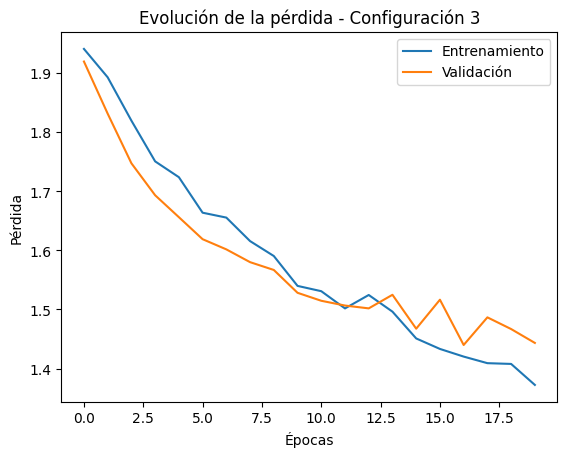

In [18]:
plt.plot(valores_perdida_train, label='Entrenamiento')
plt.plot(valores_perdida_validacion, label='Validación')

plt.xlabel('Épocas')
plt.ylabel('Pérdida')
plt.title('Evolución de la pérdida - Configuración 3')
plt.legend()
plt.show()

In [23]:
resultados.append({
    'Configuración': 3,
    'Learning rate': 0.0001,
    'Batch size': 32,
    'Filtros': '16, 32, 64',
    'Dropout': 0.50,
    'Épocas': len(valores_perdida_train),
    'Mejor val loss': round(mejor_perdida, 4),
    'Accuracy validación': round(accuracy, 2)
})

print(resultados)


[{'Configuración': 1, 'Learning rate': 0.001, 'Batch size': 32, 'Filtros': '16, 32, 64', 'Dropout': 0.25, 'Épocas': 11, 'Mejor val loss': 1.6197, 'Accuracy validación': 40.95}, {'Configuración': 3, 'Learning rate': 0.0001, 'Batch size': 32, 'Filtros': '16, 32, 64', 'Dropout': 0.5, 'Épocas': 20, 'Mejor val loss': 1.4399, 'Accuracy validación': 40.95}, {'Configuración': 2, 'Learning rate': 0.0001, 'Batch size': 32, 'Filtros': '16, 32, 64', 'Dropout': 0.25, 'Épocas': 20, 'Mejor val loss': 1.543, 'Accuracy validación': 42.22}, {'Configuración': 3, 'Learning rate': 0.0001, 'Batch size': 32, 'Filtros': '16, 32, 64', 'Dropout': 0.5, 'Épocas': 20, 'Mejor val loss': 1.4399, 'Accuracy validación': 40.95}]


In [25]:
# Configuración 4
loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

In [26]:
modelo = ConvNet().to(device)
modelo.dropout1 = nn.Dropout(p=0.5)

criterio = nn.CrossEntropyLoss()
optimizador = optim.Adam(modelo.parameters(), lr=0.0001)

epocas = 20

In [27]:
import copy

valores_perdida_train = []
valores_perdida_validacion = []

mejor_perdida = float('inf')
paciencia = 5
epocas_sin_mejora = 0

print('*** Comienza entrenamiento configuración 4')

for epoca in range(epocas):

  modelo.train()

  train_loss = 0.0
  for images, labels in loader:

    images, labels = images.to(device), labels.to(device)

    optimizador.zero_grad()

    outputs = modelo(images)
    loss = criterio(outputs, labels)
    loss.backward()
    optimizador.step()

    train_loss += loss.item()

  valores_perdida_train.append(train_loss/len(loader))

  with torch.no_grad():
    modelo.eval()

    valid_loss = 0.0
    for images, labels in val_loader:
      images, labels = images.to(device), labels.to(device)
      outputs = modelo(images)
      loss = criterio(outputs, labels)
      valid_loss += loss.item()

    valid_loss = valid_loss/len(val_loader)
    valores_perdida_validacion.append(valid_loss)

  print(f'Época {epoca+1:2d}, train loss: {valores_perdida_train[-1]:.4f} validation loss: {valid_loss:.4f}')

  if valid_loss < mejor_perdida:
    mejor_perdida = valid_loss
    mejor_modelo = copy.deepcopy(modelo.state_dict())
    epocas_sin_mejora = 0
  else:
    epocas_sin_mejora += 1

  if epocas_sin_mejora >= paciencia:
    print('*** Parada anticipada')
    break

modelo.load_state_dict(mejor_modelo)

*** Comienza entrenamiento configuración 4
Época  1, train loss: 1.9421 validation loss: 1.9193
Época  2, train loss: 1.9086 validation loss: 1.8715
Época  3, train loss: 1.8632 validation loss: 1.8216
Época  4, train loss: 1.8174 validation loss: 1.7705
Época  5, train loss: 1.7713 validation loss: 1.7336
Época  6, train loss: 1.7408 validation loss: 1.7181
Época  7, train loss: 1.7017 validation loss: 1.6614
Época  8, train loss: 1.6630 validation loss: 1.6279
Época  9, train loss: 1.6242 validation loss: 1.6145
Época 10, train loss: 1.5983 validation loss: 1.5943
Época 11, train loss: 1.5724 validation loss: 1.5647
Época 12, train loss: 1.5517 validation loss: 1.5524
Época 13, train loss: 1.5404 validation loss: 1.5419
Época 14, train loss: 1.5064 validation loss: 1.5056
Época 15, train loss: 1.4660 validation loss: 1.4958
Época 16, train loss: 1.4667 validation loss: 1.5381
Época 17, train loss: 1.4504 validation loss: 1.4720
Época 18, train loss: 1.4152 validation loss: 1.4629
Épo

<All keys matched successfully>

In [28]:
modelo.eval()

correctas = 0
total = 0

with torch.no_grad():
    for images, labels in val_loader:
        images, labels = images.to(device), labels.to(device)

        outputs = modelo(images)
        _, predicciones = torch.max(outputs, 1)

        total += labels.size(0)
        correctas += (predicciones == labels).sum().item()

accuracy = 100 * correctas / total

print(f'Accuracy de validación: {accuracy:.2f}%')

Accuracy de validación: 42.54%


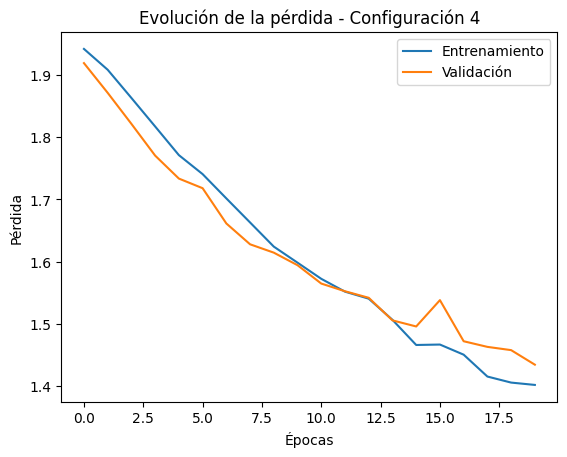

In [29]:
plt.plot(valores_perdida_train, label='Entrenamiento')
plt.plot(valores_perdida_validacion, label='Validación')

plt.xlabel('Épocas')
plt.ylabel('Pérdida')
plt.title('Evolución de la pérdida - Configuración 4')
plt.legend()
plt.show()

In [30]:
nuevo_resultado = {
    'Configuración': 4,
    'Learning rate': 0.0001,
    'Batch size': 64,
    'Filtros': '16, 32, 64',
    'Dropout': 0.50,
    'Épocas': len(valores_perdida_train),
    'Mejor val loss': round(mejor_perdida, 4),
    'Accuracy validación': round(accuracy, 2)
}

resultados = [r for r in resultados if r['Configuración'] != 4]
resultados.append(nuevo_resultado)
resultados = sorted(resultados, key=lambda r: r['Configuración'])

print(resultados)

[{'Configuración': 1, 'Learning rate': 0.001, 'Batch size': 32, 'Filtros': '16, 32, 64', 'Dropout': 0.25, 'Épocas': 11, 'Mejor val loss': 1.6197, 'Accuracy validación': 40.95}, {'Configuración': 2, 'Learning rate': 0.0001, 'Batch size': 32, 'Filtros': '16, 32, 64', 'Dropout': 0.25, 'Épocas': 20, 'Mejor val loss': 1.543, 'Accuracy validación': 42.22}, {'Configuración': 3, 'Learning rate': 0.0001, 'Batch size': 32, 'Filtros': '16, 32, 64', 'Dropout': 0.5, 'Épocas': 20, 'Mejor val loss': 1.4399, 'Accuracy validación': 40.95}, {'Configuración': 4, 'Learning rate': 0.0001, 'Batch size': 64, 'Filtros': '16, 32, 64', 'Dropout': 0.5, 'Épocas': 20, 'Mejor val loss': 1.4343, 'Accuracy validación': 42.54}]


In [31]:
class ConvNet5(nn.Module):
    def __init__(self):
        super(ConvNet5, self).__init__()

        self.conv1 = nn.Conv2d(3, 32, kernel_size=5, stride=1, padding=2)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=5, stride=1, padding=2)
        self.conv3 = nn.Conv2d(64, 128, kernel_size=5, stride=1, padding=2)

        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2, padding=0)
        self.dropout1 = nn.Dropout(p=0.5)

        self.fc1 = nn.Linear(128 * 16 * 16, 128)
        self.fc2 = nn.Linear(128, 7)

    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = self.pool1(x)

        x = self.pool1(F.relu(self.conv2(x)))
        x = self.pool1(F.relu(self.conv3(x)))

        x = x.view(-1, 128 * 16 * 16)
        x = F.relu(self.fc1(x))
        x = self.dropout1(x)
        x = self.fc2(x)

        return x

In [32]:
modelo = ConvNet5().to(device)

criterio = nn.CrossEntropyLoss()
optimizador = optim.Adam(modelo.parameters(), lr=0.0001)

epocas = 20

In [33]:
import copy

valores_perdida_train = []
valores_perdida_validacion = []
valores_accuracy_train = []
valores_accuracy_validacion = []

mejor_perdida = float('inf')
paciencia = 5
epocas_sin_mejora = 0

print('*** Comienza entrenamiento configuración 5')

for epoca in range(epocas):
    modelo.train()
    train_loss = 0.0
    correctas_train = 0
    total_train = 0

    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)

        optimizador.zero_grad()
        outputs = modelo(images)
        loss = criterio(outputs, labels)
        loss.backward()
        optimizador.step()

        train_loss += loss.item()
        _, predicciones = torch.max(outputs, 1)
        total_train += labels.size(0)
        correctas_train += (predicciones == labels).sum().item()

    valores_perdida_train.append(train_loss / len(loader))
    valores_accuracy_train.append(100 * correctas_train / total_train)

    modelo.eval()
    valid_loss = 0.0
    correctas_val = 0
    total_val = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)

            outputs = modelo(images)
            loss = criterio(outputs, labels)

            valid_loss += loss.item()
            _, predicciones = torch.max(outputs, 1)
            total_val += labels.size(0)
            correctas_val += (predicciones == labels).sum().item()

    valid_loss /= len(val_loader)
    valid_accuracy = 100 * correctas_val / total_val

    valores_perdida_validacion.append(valid_loss)
    valores_accuracy_validacion.append(valid_accuracy)

    print(
        f'Época {epoca+1:2d}, '
        f'train loss: {valores_perdida_train[-1]:.4f}, '
        f'validation loss: {valid_loss:.4f}, '
        f'validation accuracy: {valid_accuracy:.2f}%'
    )

    if valid_loss < mejor_perdida:
        mejor_perdida = valid_loss
        mejor_modelo = copy.deepcopy(modelo.state_dict())
        epocas_sin_mejora = 0
    else:
        epocas_sin_mejora += 1

    if epocas_sin_mejora >= paciencia:
        print('*** Parada anticipada')
        break

modelo.load_state_dict(mejor_modelo)

*** Comienza entrenamiento configuración 5
Época  1, train loss: 1.9306, validation loss: 1.8905, validation accuracy: 22.86%
Época  2, train loss: 1.8636, validation loss: 1.8228, validation accuracy: 28.57%
Época  3, train loss: 1.7973, validation loss: 1.7331, validation accuracy: 34.60%
Época  4, train loss: 1.7293, validation loss: 1.6950, validation accuracy: 38.10%
Época  5, train loss: 1.6648, validation loss: 1.6373, validation accuracy: 38.73%
Época  6, train loss: 1.6432, validation loss: 1.6255, validation accuracy: 36.19%
Época  7, train loss: 1.6075, validation loss: 1.6363, validation accuracy: 36.83%
Época  8, train loss: 1.5807, validation loss: 1.5657, validation accuracy: 41.90%
Época  9, train loss: 1.5352, validation loss: 1.5376, validation accuracy: 41.59%
Época 10, train loss: 1.5101, validation loss: 1.5555, validation accuracy: 42.22%
Época 11, train loss: 1.5178, validation loss: 1.5117, validation accuracy: 42.86%
Época 12, train loss: 1.4446, validation los

<All keys matched successfully>

In [34]:
modelo.eval()
correctas = 0
total = 0

with torch.no_grad():
    for images, labels in val_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = modelo(images)

        _, predicciones = torch.max(outputs, 1)
        total += labels.size(0)
        correctas += (predicciones == labels).sum().item()

accuracy = 100 * correctas / total

print(f'Accuracy de validación: {accuracy:.2f}%')

Accuracy de validación: 47.94%


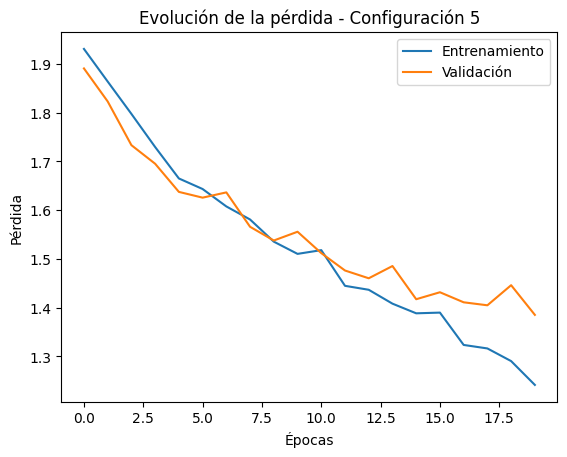

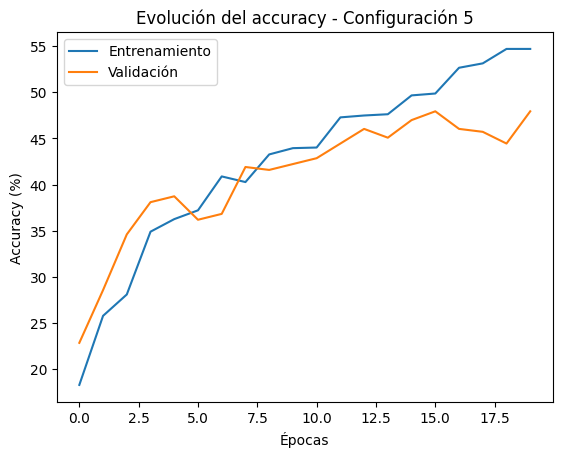

In [35]:
plt.plot(valores_perdida_train, label='Entrenamiento')
plt.plot(valores_perdida_validacion, label='Validación')
plt.xlabel('Épocas')
plt.ylabel('Pérdida')
plt.title('Evolución de la pérdida - Configuración 5')
plt.legend()
plt.show()

plt.plot(valores_accuracy_train, label='Entrenamiento')
plt.plot(valores_accuracy_validacion, label='Validación')
plt.xlabel('Épocas')
plt.ylabel('Accuracy (%)')
plt.title('Evolución del accuracy - Configuración 5')
plt.legend()
plt.show()

In [36]:
nuevo_resultado = {
    'Configuración': 5,
    'Learning rate': 0.0001,
    'Batch size': 64,
    'Filtros': '32, 64, 128',
    'Dropout': 0.50,
    'Épocas': len(valores_perdida_train),
    'Mejor val loss': round(mejor_perdida, 4),
    'Accuracy validación': round(accuracy, 2)
}

resultados = [r for r in resultados if r['Configuración'] != 5]
resultados.append(nuevo_resultado)
resultados = sorted(resultados, key=lambda r: r['Configuración'])

print(resultados)

[{'Configuración': 1, 'Learning rate': 0.001, 'Batch size': 32, 'Filtros': '16, 32, 64', 'Dropout': 0.25, 'Épocas': 11, 'Mejor val loss': 1.6197, 'Accuracy validación': 40.95}, {'Configuración': 2, 'Learning rate': 0.0001, 'Batch size': 32, 'Filtros': '16, 32, 64', 'Dropout': 0.25, 'Épocas': 20, 'Mejor val loss': 1.543, 'Accuracy validación': 42.22}, {'Configuración': 3, 'Learning rate': 0.0001, 'Batch size': 32, 'Filtros': '16, 32, 64', 'Dropout': 0.5, 'Épocas': 20, 'Mejor val loss': 1.4399, 'Accuracy validación': 40.95}, {'Configuración': 4, 'Learning rate': 0.0001, 'Batch size': 64, 'Filtros': '16, 32, 64', 'Dropout': 0.5, 'Épocas': 20, 'Mejor val loss': 1.4343, 'Accuracy validación': 42.54}, {'Configuración': 5, 'Learning rate': 0.0001, 'Batch size': 64, 'Filtros': '32, 64, 128', 'Dropout': 0.5, 'Épocas': 20, 'Mejor val loss': 1.385, 'Accuracy validación': 47.94}]
